                             model    MAE    RMSE    R2  n_test shock_features
0                  Naive (t+1 = t)  66.89  103.88  0.89     282            NaN
1  Linear Regression (with shocks)  75.36  105.31  0.89     282           True
2    Linear Regression (no shocks)  67.12   98.79  0.90     282          False
3      Random Forest (with shocks)  75.12  109.82  0.88     282           True
4        Random Forest (no shocks)  77.34  111.20  0.87     282          False


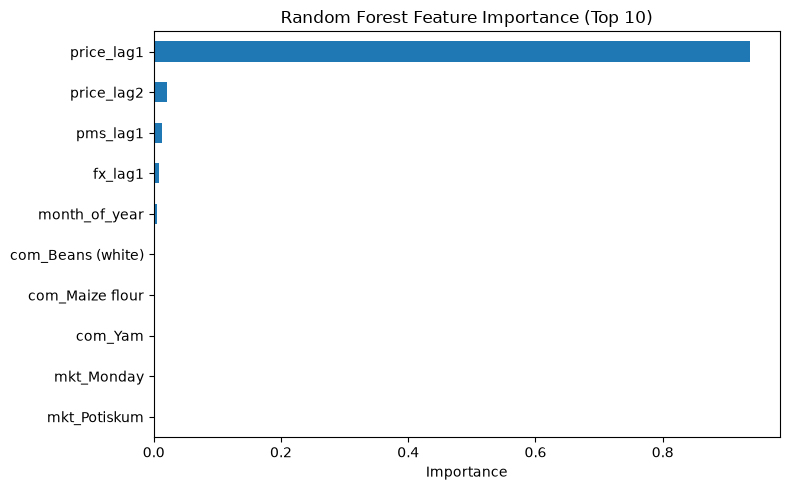

In [13]:
import os
import sys
import pathlib

# Automatically anchor working directory to the project root (nigeria-food-prices)
for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents[:3]]:
    if (p / 'src' / 'evaluation.py').exists():
        os.chdir(p)
        if str(p) not in sys.path:
            sys.path.insert(0, str(p))
        break

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from src.evaluation import (
    time_ordered_split,
    compute_regression_metrics,
    naive_baseline_metrics,
)

os.makedirs('reports/figures', exist_ok=True)

df = pd.read_csv('data/processed/master.csv', parse_dates=['month'])

TARGET = 'price_ngn'
SHOCK_COLS = ['fx_lag1', 'pms_lag1']
BASE_FEATURES = (
    ['price_lag1', 'price_lag2', 'month_of_year']
    + [c for c in df.columns if c.startswith(('mkt_', 'com_'))]
)

def get_features(include_shock: bool) -> list[str]:
    return BASE_FEATURES + (SHOCK_COLS if include_shock else [])

# Drop rows with missing lag values before splitting
df_model = df.dropna(subset=BASE_FEATURES + SHOCK_COLS + [TARGET]).copy()
train, test = time_ordered_split(df_model, date_col='month', train_ratio=0.8)

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=300, max_depth=10, random_state=42),
}

# Start results with the naive benchmark (t = t-1)
rows = [naive_baseline_metrics(test, current_price_col='price_lag1', target_col=TARGET)]

for name, model in models.items():
    for shock in [True, False]:
        feats = get_features(shock)
        model.fit(train[feats], train[TARGET])
        preds = model.predict(test[feats])
        label = f"{name} ({'with shocks' if shock else 'no shocks'})"
        metrics = compute_regression_metrics(test[TARGET], preds, model_name=label)
        metrics['shock_features'] = shock
        rows.append(metrics)

results = pd.DataFrame(rows)
print(results.round(2))
results.to_csv('reports/results_lr_rf.csv', index=False)

# Feature importance: Random Forest with shock features
feats_shock = get_features(True)
rf = RandomForestRegressor(n_estimators=300, max_depth=10, random_state=42).fit(
    train[feats_shock], train[TARGET]
)
imp = pd.Series(rf.feature_importances_, index=feats_shock).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
imp.tail(10).plot.barh(ax=ax, title='Random Forest Feature Importance (Top 10)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.savefig('reports/figures/rf_feature_importance.png', dpi=200)
plt.show()